# Examining the Main Research Question

The main research question is as follows: **'Are there differences in content between homosexual and heterosexual fan fiction published on Archive of Our Own as reflected through tags?'**

In [1]:
# Import package
import polars as pl
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df_metadata = pl.read_ndjson("./data/combined_metadata.jsonl") # Create the df_metadata DataFrame
df_metadata = df_metadata.unnest('metadata') # Turn the metadata column into 18 separate columns

fandoms = ["DC's Legends of Tomorrow (TV)", "Avatar: The Last Airbender (Cartoon 2005)", "Spider-Man: Spider-Verse (Sony Animated Movies)"]

# Select the target fandom and relationship categories
df_metadata = df_metadata.filter(
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]) |
    (pl.col("Fandom") == fandoms[2])) &
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M") |
    (pl.col("Category") == "F/M"))
)

df_metadata.head()

id,title,Additional Tags,Archive Warning,Category,Characters,Fandoms,Language,Rating,Relationship,author,chapters,completed,published,words,Fandom,Character,Collections,Series,Relationships
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""10012010""","""Just One Training""","""Explicit Sexual Content, Oral …","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""Explicit""","""Sara Lance/Leonard Snart""","""by capnwho""","""1/1""","""""","""2017-02-28""","""1,470""","""DC's Legends of Tomorrow (TV)""",null,null,"""Just One Fixation""",null
"""10013705""","""Five Months More""","""Established Relationship, surp…","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart""",null,"""English""","""Not Rated""",null,"""by flabbergabst""","""1/1""","""""","""2017-02-28""","""505""","""DC's Legends of Tomorrow (TV)""",null,null,"""The Captain Canary Collection""","""Sara Lance/Leonard Snart, Capt…"
"""10018964""","""It Ends with a Kiss""","""Alpha/Beta/Omega Dynamics, Min…","""No Archive Warnings Apply""","""M/M""","""Leonard Snart, Ray Palmer, Mic…",null,"""English""","""Teen And Up Audiences""","""Ray Palmer/Leonard Snart""","""by Constantsnow""","""1/1""","""""","""2017-02-28""","""3,008""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10030784""","""Bet""",null,"""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""General Audiences""","""Sara Lance/Leonard Snart""","""by orphan_account""","""1/1""","""""","""2017-03-01""","""1,273""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10033958""","""For the Both of Us""","""Captain Canary, ficcingcaptain…","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""Not Rated""",null,"""by flabbergabst""","""1/1""","""""","""2017-03-01""","""1,067""","""DC's Legends of Tomorrow (TV)""",null,null,"""The Captain Canary Collection""","""Sara Lance/Leonard Snart, Capt…"


In [3]:
# Count the amount of fan works per fandom and category composition
ff_mm_amt = df_metadata.filter(
    (pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")
).select(pl.len())
fm_amt = df_metadata.filter(pl.col("Category") == "F/M").select(pl.len())

print(f"""Homosexual Fan Works Amount: {ff_mm_amt}
Heterosexual Fan Works Amount: {fm_amt}""")

Homosexual Fan Works Amount: shape: (1, 1)
┌──────┐
│ len  │
│ ---  │
│ u32  │
╞══════╡
│ 5713 │
└──────┘
Heterosexual Fan Works Amount: shape: (1, 1)
┌──────┐
│ len  │
│ ---  │
│ u32  │
╞══════╡
│ 4256 │
└──────┘


## 1. Ratings

### 1.1 Creating the Ratings Datasets

In [4]:
df_ratings_ff_mm = df_metadata.filter(
    (pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")
).select(pl.col("Rating").value_counts(sort=True)).unnest("Rating").rename({"count": "Homosexual Freq"}).with_columns((pl.col("Homosexual Freq") / ff_mm_amt.item(0,0) * 100).alias("Homosexual %")) # Filtered by F/F + M/M

df_ratings_fm = df_metadata.filter(
    (pl.col("Category") == "F/M")
).select(pl.col("Rating").value_counts(sort=True)).unnest("Rating").rename({"count": "Heterosexual Freq"}).with_columns((pl.col("Heterosexual Freq") / fm_amt.item(0,0) * 100).alias("Heterosexual %")) # Filtered by F/M

print("Homosexual Ratings Amount:")
df_ratings_ff_mm.show(5)
print("Heterosexual Ratings Amount:")
df_ratings_fm.show(5)

Homosexual Ratings Amount:


Rating,Homosexual Freq,Homosexual %
str,u32,f64
"""Teen And Up Audiences""",1785,31.24453
"""General Audiences""",1362,23.840364
"""Explicit""",1175,20.567128
"""Mature""",839,14.685804
"""Not Rated""",552,9.662174


Heterosexual Ratings Amount:


Rating,Heterosexual Freq,Heterosexual %
str,u32,f64
"""Teen And Up Audiences""",1219,28.641917
"""General Audiences""",1207,28.359962
"""Explicit""",818,19.219925
"""Mature""",622,14.614662
"""Not Rated""",390,9.163534


### 1.2 Visualizing the Ratings Datasets

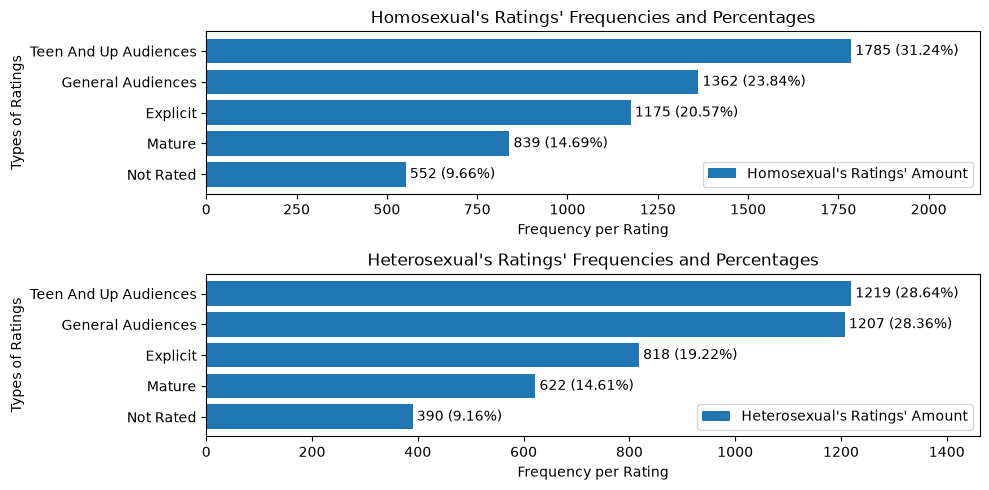

In [5]:
N = len(df_ratings_ff_mm["Rating"]) # Amount of groups
width = 0.8 # Width of the bars
ind = np.arange(N) # Position of the bars on x-axis

fig, ax = plt.subplots(2, 1, figsize=(10, 5)) # Set figure size

# Plot a horizontal bar plot
p1 = ax[0].barh(ind, df_ratings_ff_mm["Homosexual Freq"], width, label="Homosexual's Ratings' Amount")
p2 = ax[1].barh(ind, df_ratings_fm["Heterosexual Freq"], width, label="Heterosexual's Ratings' Amount")

# Combine the Frequencies and %
ff_mm_labels = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_ratings_ff_mm["Homosexual Freq"],
        df_ratings_ff_mm["Homosexual %"]
    )
]

fm_labels = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_ratings_fm["Heterosexual Freq"],
        df_ratings_fm["Heterosexual %"]
    )
]

#labels
ax[0].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[0].set_xlabel('Frequency per Rating')
ax[0].set_title('Homosexual\'s Ratings\' Frequencies and Percentages')
ax[0].set_ylabel('Types of Ratings')
ax[0].set_yticks(ind)
ax[0].set_yticklabels(df_ratings_ff_mm['Rating'])
ax[0].legend(loc='best')

ax[1].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[1].set_xlabel('Frequency per Rating')
ax[1].set_title('Heterosexual\'s Ratings\' Frequencies and Percentages')
ax[1].set_ylabel('Types of Ratings')
ax[1].set_yticks(ind)
ax[1].set_yticklabels(df_ratings_fm['Rating'])
ax[1].legend(loc='best')

ax[0].bar_label(p1, labels=ff_mm_labels, padding=3)
ax[1].bar_label(p2, labels=fm_labels, padding=3)

# Add space for the labels
ax[0].set_xlim(right=df_ratings_ff_mm["Homosexual Freq"].max() * 1.20)
ax[1].set_xlim(right=df_ratings_fm["Heterosexual Freq"].max() * 1.20)

plt.tight_layout()
plt.show()

## 2. Archive Warnings

### 2.1 Creating the Archive Warnings Datasets

In [6]:
df_aw_ff_mm = df_metadata.filter(
    (pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")
).select(pl.col("Archive Warning").value_counts(sort=True)).unnest("Archive Warning").drop_nulls().rename({"count": "Homosexual Freq"}).with_columns((pl.col("Homosexual Freq") / ff_mm_amt.item(0,0) * 100).alias("Homosexual %")) # Filtered by F/F + M/M

df_aw_fm = df_metadata.filter(
    (pl.col("Category") == "F/M")
).select(pl.col("Archive Warning").value_counts(sort=True)).unnest("Archive Warning").drop_nulls().rename({"count": "Heterosexual Freq"}).with_columns((pl.col("Heterosexual Freq") / fm_amt.item(0,0) * 100).alias("Heterosexual %")) # Filtered by F/M

print("Homosexual Archive Warnings Amount:")
df_aw_ff_mm.show(6)
print("Heterosexual Archive Warnings Amount:")
df_aw_fm.show(6)

Homosexual Archive Warnings Amount:


Archive Warning,Homosexual Freq,Homosexual %
str,u32,f64
"""No Archive Warnings Apply""",3053,53.439524
"""Creator Chose Not To Use Archi…",1722,30.141782
"""Underage Sex""",268,4.691055
"""Graphic Depictions Of Violence""",168,2.940662
"""Major Character Death""",88,1.540347
"""Rape/Non-Con""",48,0.840189


Heterosexual Archive Warnings Amount:


Archive Warning,Heterosexual Freq,Heterosexual %
str,u32,f64
"""No Archive Warnings Apply""",2345,55.098684
"""Creator Chose Not To Use Archi…",1197,28.125
"""Graphic Depictions Of Violence""",150,3.524436
"""Underage Sex""",124,2.913534
"""Major Character Death""",101,2.37312
"""Rape/Non-Con""",53,1.245301


### 2.2 Visualizing the Archive Warnings Datasets

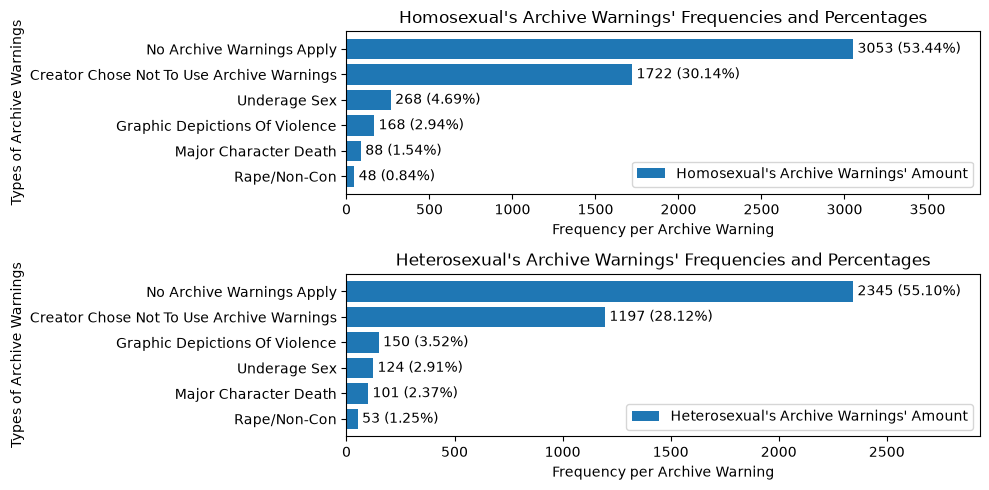

In [7]:
N = len(df_aw_ff_mm["Archive Warning"]) # Amount of groups
width = 0.8 # Width of the bars
ind = np.arange(N) # Position of the bars on x-axis

fig, ax = plt.subplots(2, 1, figsize=(10, 5)) # Set figure size

# Plot a horizontal bar plot
p1 = ax[0].barh(ind, df_aw_ff_mm["Homosexual Freq"], width, label="Homosexual's Archive Warnings' Amount")
p2 = ax[1].barh(ind, df_aw_fm["Heterosexual Freq"], width, label="Heterosexual's Archive Warnings' Amount")

# Combine the Frequencies and %
ff_mm_labels = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_aw_ff_mm["Homosexual Freq"],
        df_aw_ff_mm["Homosexual %"]
    )
]

fm_labels = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_aw_fm["Heterosexual Freq"],
        df_aw_fm["Heterosexual %"]
    )
]

#labels
ax[0].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[0].set_xlabel('Frequency per Archive Warning')
ax[0].set_title('Homosexual\'s Archive Warnings\' Frequencies and Percentages')
ax[0].set_ylabel('Types of Archive Warnings')
ax[0].set_yticks(ind)
ax[0].set_yticklabels(df_aw_ff_mm['Archive Warning'])
ax[0].legend(loc='best')

ax[1].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[1].set_xlabel('Frequency per Archive Warning')
ax[1].set_title('Heterosexual\'s Archive Warnings\' Frequencies and Percentages')
ax[1].set_ylabel('Types of Archive Warnings')
ax[1].set_yticks(ind)
ax[1].set_yticklabels(df_aw_fm['Archive Warning'])
ax[1].legend(loc='best')

ax[0].bar_label(p1, labels=ff_mm_labels, padding=3)
ax[1].bar_label(p2, labels=fm_labels, padding=3)

# Add space for the labels
ax[0].set_xlim(right=df_aw_ff_mm["Homosexual Freq"].max() * 1.25)
ax[1].set_xlim(right=df_aw_fm["Heterosexual Freq"].max() * 1.25)

plt.tight_layout()
plt.show()

## 3. Additional Tags

### 3.1 Creating the Additional Tags Datasets

In [8]:
# Read the CSV file
df_annotated_tags_fandom_category = pl.read_csv("./data/df_annotated_tags_fandom_category.csv")
df_add_tag_annotation = pl.read_csv("./data/df_additional_tag_annotations.csv")
df_annotated_tags_fandom_category.show()
df_add_tag_annotation.show()

Fandom,Category,Additional Tags,Freq,Character,Narrative,Porn,Kink
str,str,str,i64,str,str,str,str
"""Avatar: The Last Airbender (Ca…","""F/M""","""!!TW!!""",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""Avatar: The Last Airbender (Ca…","""F/M""","""""Has she always been good at t…",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""Avatar: The Last Airbender (Ca…","""F/M""","""""I love the smell of incest 😍😍…",1,"""No Character""","""No Narrative""","""Is Porn""","""Not Kink"""
"""Spider-Man: Spider-Verse (Sony…","""F/M""","""""I loved her to the point of i…",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""DC's Legends of Tomorrow (TV)""","""F/F""","""""Mayday Mayday!""""",1,"""No Character""","""Event-related/Action""","""Not Porn""","""Not Kink"""


Additional Tags,Character,Narrative,Porn,Kink
str,str,str,str,str
"""Fluff""","""No Character""","""Theme/Genre""","""Not Porn""","""Not Kink"""
"""Angst""","""No Character""","""Theme/Genre""","""Not Porn""","""Not Kink"""
"""AvaLance""","""No Character""","""Plot""","""Not Porn""","""Not Kink"""
"""Hurt/Comfort""","""Emotion/Mental State""","""No Narrative""","""Not Porn""","""Not Kink"""
"""Angst with a Happy Ending""","""No Character""","""Theme/Genre""","""Not Porn""","""Not Kink"""


In [9]:
def label_freq(df):
    """
    Calculates the frequency of the annotations.

    Parameter:
        df (DataFrame): Filtered DataFrame.
    Returns:
        df_label_freq (DataFrame): Contains the frequency of the annotations.
    """
    # Add the frequency of the annotations based on unique additional tags
    categories = ["Character", "Narrative", "Porn", "Kink"]

    df_unique_values = pl.DataFrame()
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[0]).value_counts()).unnest(categories[0]).rename({"Character": "Label"})])
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[1]).value_counts()).unnest(categories[1]).rename({"Narrative": "Label"})])
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[2]).value_counts()).unnest(categories[2]).rename({"Porn": "Label"})])
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[3]).value_counts()).unnest(categories[3]).rename({"Kink": "Label"})])
    df_unique_values = df_unique_values.rename({"count": "Unique Additional Tags Frequency"})

    # Turn into lists
    char_list = ['No Character', 'Biography', 'Physical Feature', 'Emotion/Mental State', 'Relationship', "Personality"]
    nar_list = ['No Narrative', 'Plot', 'Event-related/Action', 'Theme/Genre', 'WorldSetting', 'Narrative Methods', 'Format']
    porn_list = ['Not Porn', 'Is Porn']
    kink_list = ['Not Kink', 'Is Kink']

    # Append the frequency of the annotations based on total additional tags
    df_freq_count = pl.DataFrame()
    for char_label in char_list:
        df_temp_char = pl.DataFrame({
            "Label": char_label,
            "Freq": df.filter(pl.col("Character") == char_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_char])
    for nar_label in nar_list:
        df_temp_nar = pl.DataFrame({
            "Label": nar_label,
            "Freq": df.filter(pl.col("Narrative") == nar_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_nar])
    for porn_label in porn_list:
        df_temp_porn = pl.DataFrame({
            "Label": porn_label,
            "Freq": df.filter(pl.col("Porn") == porn_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_porn])
    for kink_label in kink_list:
        df_temp_kink = pl.DataFrame({
            "Label": kink_label,
            "Freq": df.filter(pl.col("Kink") == kink_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_kink])
    
    df_freq_count = df_freq_count.rename({"Freq": "Total Additional Tags Frequency"})

    labels = df_freq_count.to_series(0)
    df_label_freq = pl.concat([df_unique_values, df_freq_count], how='align')
    df_label_freq = df_label_freq.sort(pl.col("Total Additional Tags Frequency"), descending=True)
    
    return df_label_freq

In [12]:
character_labels = ["No Character", "Biography", "Physical Feature", "Emotion/Mental State", "Relationship", "Personality"]
narrative_labels = ["No Narrative", "Plot", "Event-related/Action", "Theme/Genre", "WorldSetting", "Narrative Methods", "Format"]
porn_labels = ["Not Porn", "Is Porn"]
kink_labels = ["Not Kink", "Is Kink"]

In [21]:
# Filtered by F/F + M/M
df_add_tags_ff_mm = df_annotated_tags_fandom_category.filter(
    (pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")
).group_by("Additional Tags").agg(pl.col("Freq").sum())
df_add_tags_ff_mm = df_add_tags_ff_mm.join(df_add_tag_annotation, on="Additional Tags") # Add annotations
df_add_tags_ff_mm = label_freq(df_add_tags_ff_mm) # Calculate annotation frequencies
df_add_tags_ff_mm = df_add_tags_ff_mm.with_columns(pl.when(pl.col("Label").is_in(character_labels)).then(pl.lit("Character")).when(pl.col("Label").is_in(narrative_labels)).then(pl.lit("Narrative")).when(pl.col("Label").is_in(porn_labels)).then(pl.lit("Porn")).when(pl.col("Label").is_in(kink_labels)).then(pl.lit("Kink")).alias("Category")) # Assign annotation category
df_add_tags_ff_mm = df_add_tags_ff_mm.with_columns((pl.col("Unique Additional Tags Frequency") / pl.col("Unique Additional Tags Frequency").sum().over("Category") * 100).alias("Unique Additional Tags in %"), (pl.col("Total Additional Tags Frequency") / pl.col("Total Additional Tags Frequency").sum().over("Category") * 100).alias("Total Additional Tags in %")) # Calculate percentages within each annotation category

# Filtered by F/M
df_add_tags_fm = df_annotated_tags_fandom_category.filter((pl.col("Category") == "F/M")).group_by("Additional Tags").agg(pl.col("Freq").sum())
df_add_tags_fm = df_add_tags_fm.join(df_add_tag_annotation, on="Additional Tags") # Add annotations
df_add_tags_fm = label_freq(df_add_tags_fm) # Calculate annotation frequencies
df_add_tags_fm = df_add_tags_fm.with_columns(pl.when(pl.col("Label").is_in(character_labels)).then(pl.lit("Character")).when(pl.col("Label").is_in(narrative_labels)).then(pl.lit("Narrative")).when(pl.col("Label").is_in(porn_labels)).then(pl.lit("Porn")).when(pl.col("Label").is_in(kink_labels)).then(pl.lit("Kink")).alias("Category")) # Assign annotation category
df_add_tags_fm = df_add_tags_fm.with_columns((pl.col("Unique Additional Tags Frequency") / pl.col("Unique Additional Tags Frequency").sum().over("Category") * 100).alias("Unique Additional Tags in %"), (pl.col("Total Additional Tags Frequency") / pl.col("Total Additional Tags Frequency").sum().over("Category") * 100).alias("Total Additional Tags in %")) # Calculate percentages within each annotation category

print("Homosexual Additional Tag Annotations' Amount:")
df_add_tags_ff_mm.show(17)
print("Heterosexual Additional Tag Annotations' Amount:")
df_add_tags_fm.show(17)

df_add_tags_ff_mm = df_add_tags_ff_mm.filter(
    (pl.col("Label") != "Not Kink") &
    (pl.col("Label") != "Not Porn")
)
df_add_tags_fm = df_add_tags_fm.filter(
    (pl.col("Label") != "Not Kink") &
    (pl.col("Label") != "Not Porn")
)

print("Homosexual Additional Tag Annotations' Amount:")
df_add_tags_ff_mm.show(17)
print("Heterosexual Additional Tag Annotations' Amount:")
df_add_tags_fm.show(17)

Homosexual Additional Tag Annotations' Amount:


Label,Unique Additional Tags Frequency,Total Additional Tags Frequency,Category,Unique Additional Tags in %,Total Additional Tags in %
str,u32,i64,str,f64,f64
"""Not Kink""",16296,44941,"""Kink""",97.574996,95.107189
"""Not Porn""",15440,41031,"""Porn""",92.449554,86.832582
"""No Character""",10211,24592,"""Character""",61.140051,52.043257
"""No Narrative""",9635,19911,"""Narrative""",57.691156,42.137007
"""Event-related/Action""",2904,11232,"""Narrative""",17.38818,23.769919
"""Relationship""",2128,8102,"""Character""",12.741752,17.146001
"""Biography""",2388,7075,"""Character""",14.298545,14.972594
"""Is Porn""",1261,6222,"""Porn""",7.550446,13.167418
"""Theme/Genre""",1043,5848,"""Narrative""",6.245135,12.375934


Heterosexual Additional Tag Annotations' Amount:


Label,Unique Additional Tags Frequency,Total Additional Tags Frequency,Category,Unique Additional Tags in %,Total Additional Tags in %
str,u32,i64,str,f64,f64
"""Not Kink""",11857,33867,"""Kink""",97.588477,95.033252
"""Not Porn""",11173,30287,"""Porn""",91.958848,84.987513
"""No Character""",7454,19079,"""Character""",61.349794,53.537054
"""No Narrative""",6737,14163,"""Narrative""",55.44856,39.742403
"""Event-related/Action""",2190,8452,"""Narrative""",18.024691,23.716923
"""Relationship""",1654,6119,"""Character""",13.613169,17.170357
"""Is Porn""",977,5350,"""Porn""",8.041152,15.012487
"""Biography""",1694,4981,"""Character""",13.942387,13.977046
"""Theme/Genre""",844,4936,"""Narrative""",6.946502,13.850773


Homosexual Additional Tag Annotations' Amount:


Label,Unique Additional Tags Frequency,Total Additional Tags Frequency,Category,Unique Additional Tags in %,Total Additional Tags in %
str,u32,i64,str,f64,f64
"""No Character""",10211,24592,"""Character""",61.140051,52.043257
"""No Narrative""",9635,19911,"""Narrative""",57.691156,42.137007
"""Event-related/Action""",2904,11232,"""Narrative""",17.38818,23.769919
"""Relationship""",2128,8102,"""Character""",12.741752,17.146001
"""Biography""",2388,7075,"""Character""",14.298545,14.972594
"""Is Porn""",1261,6222,"""Porn""",7.550446,13.167418
"""Theme/Genre""",1043,5848,"""Narrative""",6.245135,12.375934
"""Emotion/Mental State""",1454,5490,"""Character""",8.706066,11.61831
"""Plot""",1288,4533,"""Narrative""",7.712113,9.593042


Heterosexual Additional Tag Annotations' Amount:


Label,Unique Additional Tags Frequency,Total Additional Tags Frequency,Category,Unique Additional Tags in %,Total Additional Tags in %
str,u32,i64,str,f64,f64
"""No Character""",7454,19079,"""Character""",61.349794,53.537054
"""No Narrative""",6737,14163,"""Narrative""",55.44856,39.742403
"""Event-related/Action""",2190,8452,"""Narrative""",18.024691,23.716923
"""Relationship""",1654,6119,"""Character""",13.613169,17.170357
"""Is Porn""",977,5350,"""Porn""",8.041152,15.012487
"""Biography""",1694,4981,"""Character""",13.942387,13.977046
"""Theme/Genre""",844,4936,"""Narrative""",6.946502,13.850773
"""Emotion/Mental State""",1020,3890,"""Character""",8.395062,10.915621
"""Plot""",928,3543,"""Narrative""",7.63786,9.941914


### 3.2 Visualizing the Additional Tags Datasets

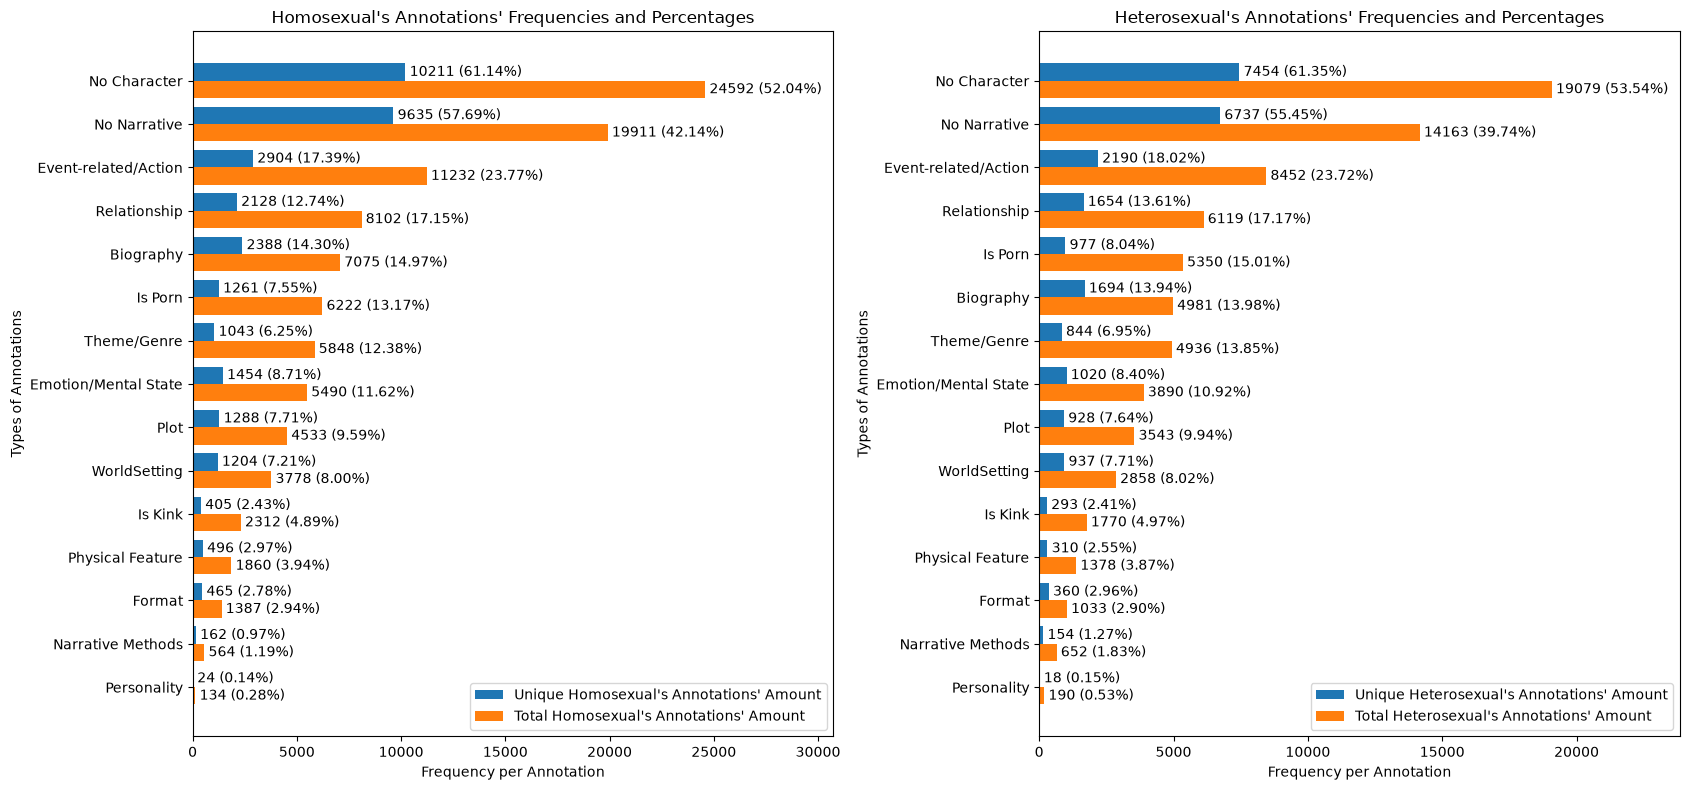

In [22]:
N = len(df_add_tags_ff_mm["Label"]) # Amount of groups
width = 0.4 # Width of the bars
ind = np.arange(N) # Position of the bars on x-axis

fig, ax = plt.subplots(1, 2, figsize=(17, 8)) # Set figure size

# Homosexual Additional Tags
# Plot a horizontal bar plot
p1 = ax[0].barh(ind, df_add_tags_ff_mm["Unique Additional Tags Frequency"], width, label="Unique Homosexual's Annotations' Amount")
p2 = ax[0].barh(ind + width, df_add_tags_ff_mm["Total Additional Tags Frequency"], width, label="Total Homosexual's Annotations' Amount")

# Combine the Frequencies and %
ff_mm_labels_unique = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_add_tags_ff_mm["Unique Additional Tags Frequency"],
        df_add_tags_ff_mm["Unique Additional Tags in %"]
    )
]

ff_mm_labels_total = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_add_tags_ff_mm["Total Additional Tags Frequency"],
        df_add_tags_ff_mm["Total Additional Tags in %"]
    )
]

#labels
ax[0].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[0].set_xlabel('Frequency per Annotation')
ax[0].set_title('Homosexual\'s Annotations\' Frequencies and Percentages')
ax[0].set_ylabel('Types of Annotations')
ax[0].set_yticks(ind + width * 0.5)
ax[0].set_yticklabels(df_add_tags_ff_mm['Label'])
ax[0].legend(loc='best')

ax[0].bar_label(p1, labels=ff_mm_labels_unique, padding=3)
ax[0].bar_label(p2, labels=ff_mm_labels_total, padding=3)

# Add space for the labels
ax[0].set_xlim(right=df_add_tags_ff_mm["Total Additional Tags Frequency"].max() * 1.25)

# Heterosexual Additional Tags
p1 = ax[1].barh(ind, df_add_tags_fm["Unique Additional Tags Frequency"], width, label="Unique Heterosexual's Annotations' Amount")
p2 = ax[1].barh(ind + width, df_add_tags_fm["Total Additional Tags Frequency"], width, label="Total Heterosexual's Annotations' Amount")

# Combine the Frequencies and %
fm_labels_unique = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_add_tags_fm["Unique Additional Tags Frequency"],
        df_add_tags_fm["Unique Additional Tags in %"]
    )
]

fm_labels_total = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_add_tags_fm["Total Additional Tags Frequency"],
        df_add_tags_fm["Total Additional Tags in %"]
    )
]

#labels
ax[1].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[1].set_xlabel('Frequency per Annotation')
ax[1].set_title('Heterosexual\'s Annotations\' Frequencies and Percentages')
ax[1].set_ylabel('Types of Annotations')
ax[1].set_yticks(ind + width * 0.5)
ax[1].set_yticklabels(df_add_tags_fm['Label'])
ax[1].legend(loc='best')

ax[1].bar_label(p1, labels=fm_labels_unique, padding=3)
ax[1].bar_label(p2, labels=fm_labels_total, padding=3)

# Add space for the labels
ax[1].set_xlim(right=df_add_tags_fm["Total Additional Tags Frequency"].max() * 1.25)

plt.tight_layout()
plt.show()